In [3]:
import os
import pandas as pd

# -----------------------------
# Configuración de rutas
# -----------------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\subset_sinSNOW_filtrMIN\Base de datos_Indices_filtrada"
output_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v"
os.makedirs(output_dir, exist_ok=True)

# -----------------------------
# Recorrer archivos CSV
# -----------------------------
for archivo in os.listdir(input_dir):
    if archivo.endswith(".csv"):
        ruta = os.path.join(input_dir, archivo)
        nombre = archivo.replace("_sin_periodo_nieve_filtr_3_12.csv", "")
        
        try:
            df = pd.read_csv(ruta, sep=";", encoding="latin1")
            if "NDWI_V" not in df.columns:
                print(f"⚠️ NDWI_v no encontrado en {archivo}")
                continue

            df["FECHA"] = pd.to_datetime(df["FECHA"], format="%Y-%m-%d", errors="coerce")
            df = df.dropna(subset=["FECHA", "NDWI_V"])
            df["YEAR"] = df["FECHA"].dt.year

            df["NDWI_v"] = pd.to_numeric(df["NDWI_V"], errors="coerce")
            resumen = df.groupby("YEAR")["NDWI_V"].agg(
                MEDIA_NDWI_v="mean",
                STD_NDWI_v="std"
            ).reset_index()

            salida = os.path.join(output_dir, f"NDWI_v_{nombre}_anual.csv")
            resumen.to_csv(salida, sep=";", index=False)
            print(f"✅ Guardado resumen anual de {nombre} en: {salida}")

        except Exception as e:
            print(f"❌ Error procesando {archivo}: {e}")

print("\n🎯 Todos los archivos procesados.")


✅ Guardado resumen anual de Bassa_Nera en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Bassa_Nera_anual.csv
✅ Guardado resumen anual de Clots_de_Rialba en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Clots_de_Rialba_anual.csv
✅ Guardado resumen anual de Estanyeres en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Estanyeres_anual.csv
✅ Guardado resumen anual de Plan_deth_Horn en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Plan_deth_Horn_anual.csv
✅ Guardado resumen anual de Pla_de_Sartari en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Pla_de_Sartari_anual.csv
✅ Guardado resumen anual de Pleta_de_Molieres en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\NDWI_v_Pleta_de_Molieres_anual.csv

🎯 Todos los archivos procesados.


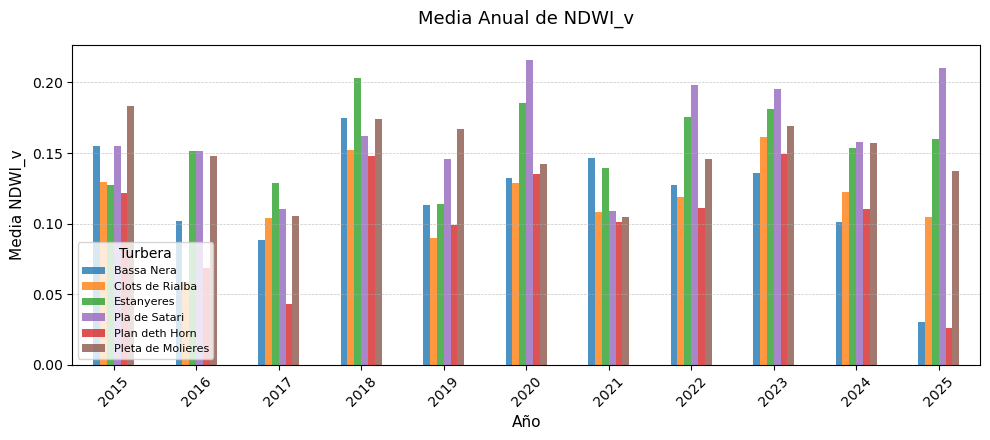

✅ Gráfico guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\grafico_media_NDWI_v_turberas.png


In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuración de rutas
# -----------------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v"
output_path = os.path.join(input_dir, "grafico_media_NDWI_v_turberas.png")

# -----------------------------
# Colores personalizados
# -----------------------------
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# -----------------------------
# Lectura de archivos
# -----------------------------
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_anual.csv"):
        nombre = file.replace("NDWI_v_", "").replace("_anual.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs, ignore_index=True)

# -----------------------------
# Preparar datos para gráfico
# -----------------------------
pivot = df_total.pivot(index="YEAR", columns="Turbera", values="MEDIA_NDWI_v")

# -----------------------------
# Crear gráfico
# -----------------------------
ax = pivot.plot(kind="bar", figsize=(10, 5),
                color=[colores.get(col, "#333333") for col in pivot.columns],
                alpha=0.8)

plt.title("Media Anual de NDWI_v", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Media NDWI_v", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda interna
plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(0, 0.40), fontsize=8, frameon=True, framealpha=0.8)

# Ajustes finales
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Gráfico guardado en: {output_path}")


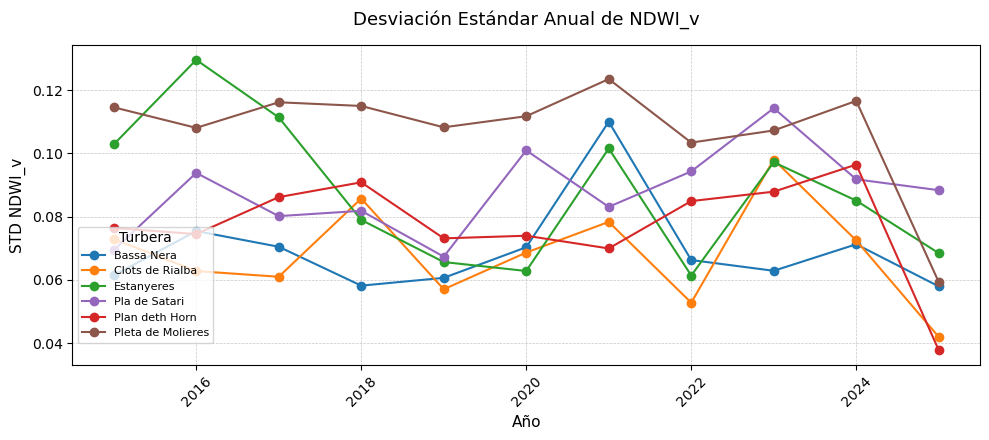

✅ Gráfico de desviación estándar guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\grafico_std_NDWI_v_turberas.png


In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Configuración de rutas
# -----------------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v"
output_path = os.path.join(input_dir, "grafico_std_NDWI_v_turberas.png")

# -----------------------------
# Colores por turbera
# -----------------------------
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# -----------------------------
# Leer todos los archivos y combinar
# -----------------------------
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_anual.csv"):
        nombre = file.replace("NDWI_v_", "").replace("_anual.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs, ignore_index=True)

# -----------------------------
# Crear gráfico de líneas con puntos
# -----------------------------
plt.figure(figsize=(10, 5))

for turbera, grupo in df_total.groupby("Turbera"):
    plt.plot(grupo["YEAR"], grupo["STD_NDWI_v"], marker="o", label=turbera, color=colores.get(turbera, "#333333"))

plt.title("Desviación Estándar Anual de NDWI_v", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("STD NDWI_v", fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda
plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(0, 0.45), fontsize=8, frameon=True, framealpha=0.8)

# Ajuste y guardado
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Gráfico de desviación estándar guardado en: {output_path}")


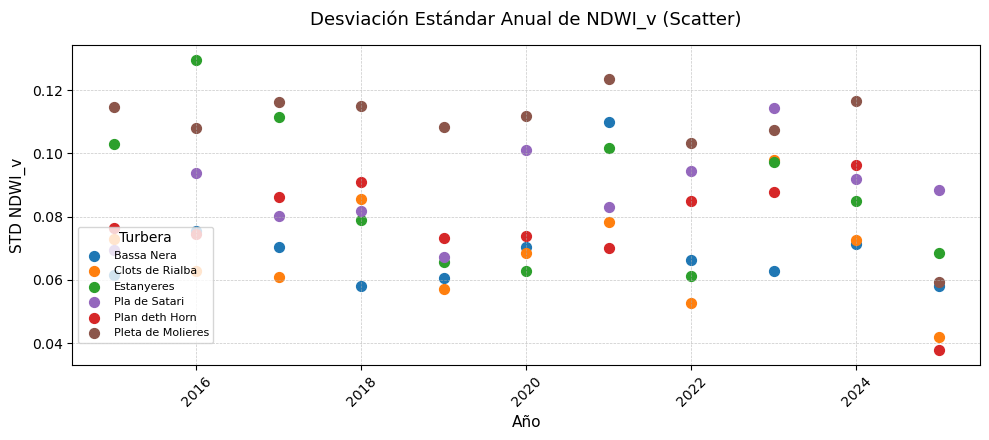

✅ Scatter plot guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\scatter_std_NDWI_v_turberas.png


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Rutas
# -----------------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v"
output_path = os.path.join(input_dir, "scatter_std_NDWI_v_turberas.png")

# -----------------------------
# Colores por turbera
# -----------------------------
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# -----------------------------
# Leer y combinar archivos
# -----------------------------
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_anual.csv"):
        nombre = file.replace("NDWI_v_", "").replace("_anual.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs, ignore_index=True)

# -----------------------------
# Crear scatter plot
# -----------------------------
plt.figure(figsize=(10, 5))

for turbera, grupo in df_total.groupby("Turbera"):
    plt.scatter(grupo["YEAR"], grupo["STD_NDWI_v"], label=turbera, color=colores.get(turbera, "#333333"), s=50)

plt.title("Desviación Estándar Anual de NDWI_v (Scatter)", fontsize=13, pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("STD NDWI_v", fontsize=11)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(title="Turbera", loc="upper left", bbox_to_anchor=(0, 0.45), fontsize=8, frameon=True, framealpha=0.8)

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Scatter plot guardado en: {output_path}")


C:\Users\farin\AppData\Local\Temp\ipykernel_7236\1049251594.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\farin\AppData\Local\Temp\ipykernel_7236\1049251594.py:41: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


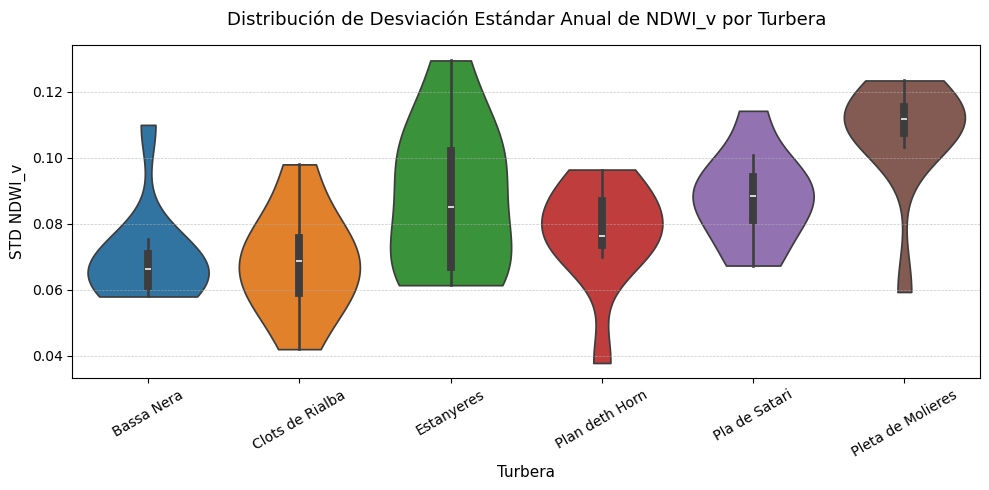

✅ Gráfico de violín guardado en: M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v\violin_std_NDWI_v_turberas.png


In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Rutas
# -----------------------------
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDWI_v"
output_path = os.path.join(input_dir, "violin_std_NDWI_v_turberas.png")

# -----------------------------
# Colores por turbera
# -----------------------------
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# -----------------------------
# Leer y combinar archivos
# -----------------------------
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_anual.csv"):
        nombre = file.replace("NDWI_v_", "").replace("_anual.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs, ignore_index=True)

# -----------------------------
# Gráfico de violín con seaborn
# -----------------------------
plt.figure(figsize=(10, 5))
sns.violinplot(
    x="Turbera",
    y="STD_NDWI_v",
    data=df_total,
    palette=colores,
    cut=0,
    scale="width",
    inner="box"  # también puedes usar "point", "quartile", "stick", etc.
)

plt.title("Distribución de Desviación Estándar Anual de NDWI_v por Turbera", fontsize=13, pad=15)
plt.xlabel("Turbera", fontsize=11)
plt.ylabel("STD NDWI_v", fontsize=11)
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Gráfico de violín guardado en: {output_path}")
